# Лекция 10. Многомерное интегрирование и стохастические методы

В предыдущей лекции мы научились вычислять одномерные интегралы
квадратурными формулами. Вся практическая механика того разбора
переносится на многомерный случай, но появляется новое качество задач:
с ростом числа переменных $d$ цена любой сеточной кубатуры растёт
экспоненциально — это называют **проклятием размерности** (curse of
dimensionality), а спасает от него **метод Монте-Карло** (Monte Carlo) —
стохастическая оценка, у которой погрешность падает как $N^{-1/2}$
независимо от $d$.

План лекции:

1. Кубатурные формулы: тензорное произведение одномерных правил;
2. проклятие размерности: почему сеточные методы сдаются;
3. метод Монте-Карло: несмещённая оценка, закон больших чисел,
   центральная предельная теорема;
4. вероятностный анализ и статистика: доверительные интервалы,
   оценка $\hat\sigma$, вероятности попадания (редкие события);
5. снижение дисперсии: antithetic variates, control variates,
   importance sampling;
6. сравнение: когда брать кубатуру, когда Монте-Карло;
7. итоги и куда это пойдёт.

> ❓ **Вопрос лекции:** сколько вычислений $f$ нужно, чтобы посчитать
> $d$-мерный интеграл с точностью $\varepsilon$ — и почему ответ
> «экспонента по $d$» для сеточных формул и «в корнях» для
> Монте-Карло?

Раз в прошлой лекции сквозным примером был

$$
I_0 = \int_0^1 e^{-x^2}\,dx = \frac{\sqrt{\pi}}{2}\,\mathrm{erf}(1) =
 0.746824132812\ldots,
$$

то здесь берём его $d$-мерную версию:

$$
I_d := \int_{[0,1]^d} f(x)\,dx,\qquad
f(x) = \prod_{k=1}^{d} e^{-x_k^2} = e^{-(x_1^2 + \dots + x_d^2)},
\qquad I_d = I_0^{\,d},
$$

— точное значение известно при любом $d$ (редкая роскошь; она позволит
проверять каждый метод с любой строгостью). Вторая классическая задача —
вероятность попадания в шар для $d$-мерного нормального вектора — тоже
выписывается точно при любом $d$.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import math
plt.rcParams['figure.dpi'] = 110

rng = np.random.default_rng(7)          # генератор случайных чисел

# сквозной пример: I_d = I0^d, f(x) = exp(-|x|^2) на кубе [0,1]^d
f0 = lambda t: np.exp(-t ** 2)
I0 = math.sqrt(math.pi) / 2 * math.erf(1.0)
J1 = math.sqrt(math.pi / 8) * math.erf(math.sqrt(2))   # ∫₀¹ e^(-2x²) dx
I_of_d = lambda d: I0 ** d
M2 = 2.0                                # max |d²f/dx_k²| = 2 по каждой оси
print(f'сквозной пример: I_d = I0^d,  I0 = {I0:.15f},  J1 = {J1:.9f}')
for d in [1, 2, 4, 6, 10, 20]:
    print(f'  d={d:2d}: I_d = I0^d = {I_of_d(d):.9f}')


сквозной пример: I_d = I0^d,  I0 = 0.746824132812427,  J1 = 0.598144007
  d= 1: I_d = I0^d = 0.746824133
  d= 2: I_d = I0^d = 0.557746285
  d= 4: I_d = I0^d = 0.311080919
  d= 6: I_d = I0^d = 0.173504227
  d=10: I_d = I0^d = 0.053973854
  d=20: I_d = I0^d = 0.002913177


## 1. 🧮 Кубатурные формулы: тензорное произведение одномерных правил

📖 **Определение.** **Кубатурной формулой** (многомерной квадратурной
формулой) называется приближённое равенство

$$
I := \int_{\Omega} f(x)\,dx \:\approx\: \sum_{j=0}^{n} A_j\, f(x_j),
\qquad \Omega \subset \mathbb{R}^d,
$$

где $x_j \in \Omega$ — узлы, $A_j$ — веса, а погрешность — остаточный
член. Всё, что мы знали об узлах, весах и остаточном члене в лекции 9,
работает здесь дословно (при $d = 1$ кубатурная формула — просто
квадратурная).

Самая важная конструкция — **тензорное произведение одномерных правил**.
Разобьём куб $[0,1]^d$ на клетки с шагом $h$ по каждой оси; на каждой
клетке применяем одномерное правило с узлами и весами $(\xi_s, w_s)$,
$s = 0..n$, а результаты перемножаются по осям:

$$
I \approx T_d(h) = \sum_{s_1=0}^{n}\cdots\sum_{s_d=0}^{n}
w_{s_1}\cdots w_{s_d}\, f(\xi_{s_1}, \dots, \xi_{s_d}),
$$

— то есть суммируем по всем узлам полной $d$-мерной сетки. Число узлов:

$$
N = (n + 1)^d \approx n^d,
$$

— и это первый главный вывод: цена сеточной кубатуры растёт
**экспоненциально по числу переменных**.

Остаточный член в тензорной конструкции складывается по осям. Для
правила средней точки локальная ошибка клетки (формула Тейлора из
лекции 9) равна $r_{\text{лок}} = \tfrac{h^3}{24} f''(\tilde\xi)$; по
каждой из $d$ осей такие члены интегрируются остальными переменными,
и после суммирования по всем осям получаем оценку

$$
|r_T| \le \frac{d\,M_2\,I_0^{\,d-1}\,h^2}{24},
\qquad h = \frac{1}{n},
$$

где $M_2 = \max_k \bigl|\partial^2 f/\partial x_k^2\bigr|$, а множитель
$I_0^{d-1} \le 1$ пришёл от интегрирования остальных осей (на сквозном
примере). Тот же механизм для правила порядка $p$ даёт
$|r_T| = O(h^p)$ с коэффициентом, растущим примерно пропорционально $d$.

Требование гладкости переносится дословно: для правила порядка $p$
нужны непрерывные частные производные до порядка $p$ включительно.
Проблемные места (изломы, нерегулярность) — та же история, что в
лекции 9: порядковая скорость теряется.

Проверяем численно на тензорном правиле **Симпсона** (порядок $p = 4$,
$|r_T| = O(h^4) = O(N^{-4/d})$).


тензорное правило Симпсона, сквозной пример I_d:
   n |  узлов (d=2)   |I−T| d=2 |  узлов (d=4)   |I−T| d=4
   4 |           25    4.67e-05 |          625    5.21e-05
   8 |           81    2.97e-06 |         6561    3.31e-06
  16 |          289    1.86e-07 |        83521    2.08e-07
  32 |         1089    1.16e-08 |      1185921    1.30e-08
порядок ошибки O(h^4) сохраняется при росте d (коэффициент типично ~ d)


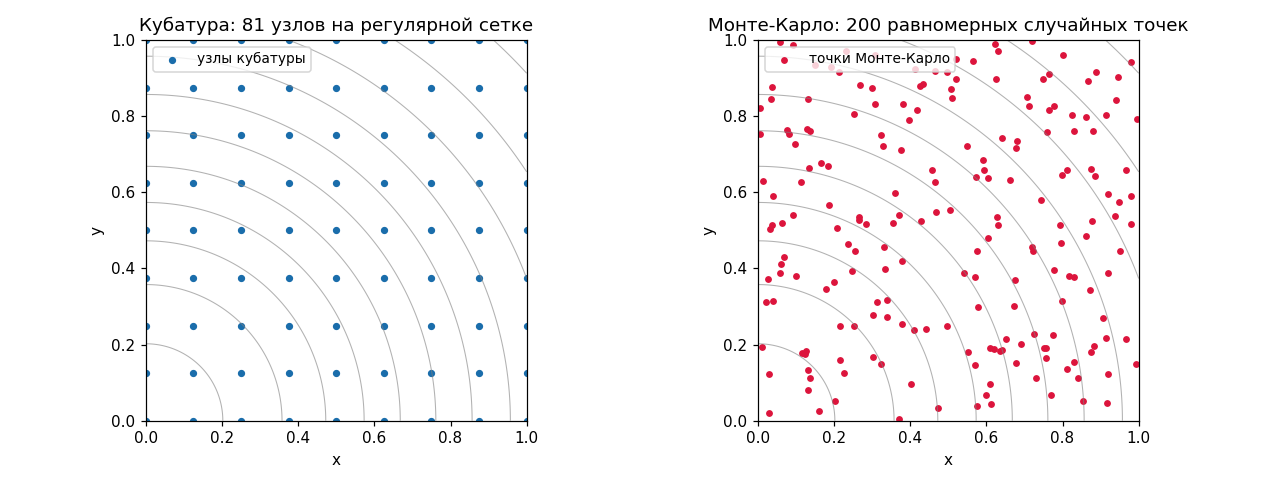

In [ ]:
def simpson_weights(n):
    # веса правила Симпсона на n отрезках (n+1 узлов), шаг h = 1/n
    h = 1 / n
    w = np.ones(n + 1)
    w[1::2] = 4
    w[2:-1:2] = 2
    return w * h / 3

def tensor_simpson_separ(d, n):
    # тензорный Симпсон для сепарабельной f: (w·f(x_s))^d — по осям одинаково
    xs = np.linspace(0, 1, n + 1)
    return (simpson_weights(n) @ f0(xs)) ** d

print('тензорное правило Симпсона, сквозной пример I_d:')
print(f"{'n':>4} | {'узлов (d=2)':>12} {'|I−T| d=2':>11} | "
      f"{'узлов (d=4)':>12} {'|I−T| d=4':>11}")
for n in [4, 8, 16, 32]:
    e2 = abs(tensor_simpson_separ(2, n) - I_of_d(2))
    e4 = abs(tensor_simpson_separ(4, n) - I_of_d(4))
    print(f'{n:4d} | {(n + 1) ** 2:12d} {e2:11.2e} | '
          f'{(n + 1) ** 4:12d} {e4:11.2e}')
print('порядок ошибки O(h^4) сохраняется при росте d (коэффициент типично ~ d)')

# 2D-картина: сетка кубатуры против случайных точек Монте-Карло
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4))
n_grid = 8
gs = np.linspace(0, 1, n_grid + 1)
GX, GY = np.meshgrid(gs, gs)
ts = np.linspace(0, 1, 300)
T, Q = np.meshgrid(ts, ts)
Z = np.exp(-(T ** 2 + Q ** 2))
for ax in axes:
    ax.contour(T, Q, Z, levels=10, colors='gray',
               linewidths=0.7, alpha=0.6)
    ax.set_xlabel('x'); ax.set_ylabel('y')
    ax.set_aspect('equal')
axes[0].scatter(GX.ravel(), GY.ravel(), s=14, c='#1a6dab',
                label='узлы кубатуры')
axes[0].set_title(f'Кубатура: {(n_grid + 1) ** 2} узлов на регулярной сетке')
mc = rng.random((200, 2))
axes[1].scatter(mc[:, 0], mc[:, 1], s=12, c='crimson',
                label='точки Монте-Карло')
axes[1].set_title('Монте-Карло: 200 равномерных случайных точек')
axes[0].legend(loc='upper left', fontsize=9)
axes[1].legend(loc='upper left', fontsize=9)
plt.tight_layout(); plt.show()


## 2. 🧟 Проклятие размерности: почему сеточные методы сдаются

Соберём выводы §1 в одну формулу. Тензорное правило порядка $p$
(средней точки и трапеций $p = 2$, Симпсона $p = 4$; гауссовы
квадратуры — любые $p$) на кубе имеет ошибку $O(h^p)$, где $h$ — шаг
по каждой из $d$ осей, а узлов $N \approx h^{-d}$. Подставляя
$h = N^{-1/d}$, получаем **главное соотношение размерности**:

$$
|r_T| = O\bigl(N^{-p/d}\bigr).
$$

Пока $d$ мало, это прекрасно. Но с ростом $d$ показатель $p/d$ тает:
при $d = 10$ и Симпсоне ($p = 4$) десятикратный рост числа узлов
уменьшает ошибку лишь в $10^{4/10} \approx 2.5$ раза (а при $d=1$ —
в $10^4$ раз). Чтобы получить $\varepsilon$, нужно
$N \sim C\,\varepsilon^{-d/p}$ вычислений $f$ — **экспонента по $d$**.
Это и называют **проклятием размерности** (curse of dimensionality,
термин Р. Беллмана, 1957).

Сравним с Монте-Карло заранее: как увидим в §3, у него ошибка
$O(N^{-1/2})$ — так что **порог** наступает, когда $p/d < 1/2$, то есть при

$$
d > 2p .
$$

Для правил порядка 2 порог $d > 4$; для Симпсона ($p = 4$) — $d > 8$.
Дальше Монте-Карло не оставляет выбора.

Посчитаем сквозной пример изнутри: сколько узлов надо сеточным формулам
для $\varepsilon = 10^{-3}$. Граница
$|r_T| \le \tfrac{d\,M_2 h^2}{24} \le \varepsilon$ даёт
$n_d = \lceil\sqrt{d\,M_2/(24\,\varepsilon)}\rceil = \lceil\sqrt{d/(12\,\varepsilon)}\rceil$
узловых интервалов по каждой оси (при $M_2 = 2$) — и $n_d^{\,d}$ узлов
итого. Против того — требование Монте-Карло
$N \approx (1.96\,\sigma_d/\varepsilon)^2$, где
$\sigma_d^2 = \mathrm{Var}\,f$ на кубе
$= \mathbb{E}f^2 - I_d^2 = J_1^d - I_0^{2d}$
(обе величины для сепарабельной f точно: $\mathbb{E}f^2 = J_1^d$,
потому что $\int_0^1 e^{-2x^2}dx = J_1$).


бюджет точности ε = 1e-3: сеточное правило средней точки vs Монте-Карло
  d | n_d по оси |   узлов n_d^d |  sigma_d  N Монте-Карло
  1 |         10 |      1.00e+01 |   0.2010         155192
  2 |         13 |      1.69e+02 |   0.2161         179385
  4 |         19 |      1.30e+05 |   0.1767         119983
  6 |         23 |      1.48e+08 |   0.1253          60286
  8 |         26 |      2.09e+11 |   0.0838          26969
 10 |         29 |      4.21e+14 |   0.0543          11329
 16 |         37 |      1.23e+25 |   0.0134            694
 20 |         41 |      1.80e+32 |   0.0051             99


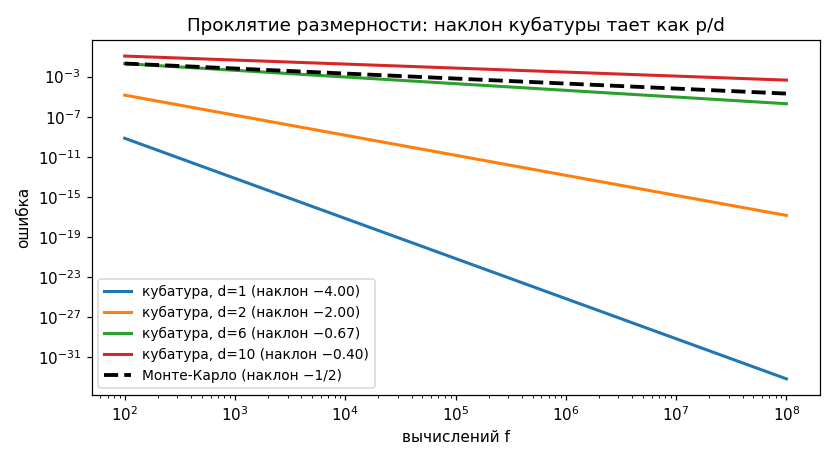

In [ ]:
var_of_d = lambda d: max(J1 ** d - I_of_d(d) ** 2, 0.0)

eps = 1e-3
print(f'бюджет точности ε = 1e-3: сеточное правило средней точки vs Монте-Карло')
print(f"{'d':>3} | {'n_d по оси':>10} | {'узлов n_d^d':>13} | "
      f"{'sigma_d':>8} {'N Монте-Карло':>14}")
for d in [1, 2, 4, 6, 8, 10, 16, 20]:
    nd = math.ceil(math.sqrt(d * M2 / (24 * eps)))
    sig = math.sqrt(var_of_d(d))
    Nmc = (1.96 * sig / eps) ** 2
    print(f'{d:3d} | {nd:10d} | {nd ** d:13.2e} | {sig:8.4f} {Nmc:14.0f}')

# график: наклон ошибки кубатуры (−p/d) против Монте-Карло (−1/2)
fig, ax = plt.subplots(figsize=(7.6, 4.2))
nodes_log = np.logspace(2, 8, 80)
p = 4                                   # Симпсон
for d in [1, 2, 6, 10]:
    err_cub = 0.07 * d * nodes_log ** (-p / d)   # C_d ≈ (M4/180)·d на сегм.
    ax.loglog(nodes_log, err_cub, lw=2,
              label=f'кубатура, d={d} (наклон −{p / d:.2f})')
err_mc = 0.2 * nodes_log ** -0.5        # 1.96·sigma_d/√N, sigma_d ≈ 0.2
ax.loglog(nodes_log, err_mc, 'k--', lw=2.5, label='Монте-Карло (наклон −1/2)')
ax.set_xlabel('вычислений f')
ax.set_ylabel('ошибка')
ax.legend(fontsize=9)
ax.set_title('Проклятие размерности: наклон кубатуры тает как p/d')
plt.tight_layout(); plt.show()


## 3. 🎲 Метод Монте-Карло

**Идея.** Превратим интеграл в математическое ожидание. Если $X$ —
случайная точка, равномерно распределённая на $\Omega$, то

$$
I = \int_\Omega f(x)\,dx = |\Omega|\;\mathbb{E}\,f(X)
$$

(доказательство: для равномерного закона плотность равна
$1/|\Omega|$, поэтому
$\mathbb{E}\,f(X) = \int_\Omega f(x)\,\frac{dx}{|\Omega|}$, и объём
$|\Omega|$ выходит наружу). Дальше оцениваем математическое ожидание
стохастически: выбираем $N$ независимых точек $X_1, \dots, X_N$ и
строим **выборочное среднее**

$$
I_N := \frac{|\Omega|}{N}\sum_{j=1}^{N} f(X_j).
$$

У этой оценки четыре столпа — приводим их полностью.

1. **Несмещённость.** Математическое ожидание линейно, а точки
   распределены одинаково:

$$
\mathbb{E}\,I_N = \frac{|\Omega|}{N}\sum_{j=1}^{N}\mathbb{E}\,f(X_j)
= |\Omega|\,\mathbb{E}\,f(X) = I .
$$

2. **Дисперсия оценки** (независимость точек, $\mathrm{Var}\,f =
   \sigma^2$):

$$
\mathrm{Var}\,I_N = \frac{|\Omega|^2}{N^2}\sum_{j=1}^{N}
\mathrm{Var}\,f(X_j) = \frac{|\Omega|^2\,\sigma^2}{N}.
$$

3. **Закон больших чисел.** Неравенство Чебышёва
   ($P(|Y-\mathbb{E}Y| \ge \varepsilon) \le \mathrm{Var}\,Y/\varepsilon^2$,
   которое следует из неравенства Маркова
   $P(|Y|\ge t)\le \mathbb{E}Y^2/t^2$, применённого к $Y = I_N - I$) даёт

$$
P\bigl(|I_N - I| \ge \varepsilon\bigr) \le
\frac{|\Omega|^2\sigma^2}{N\,\varepsilon^2} \xrightarrow[N\to\infty]{} 0 .
$$

4. **Центральная предельная теорема.** При больших $N$ случайная
   величина $\sqrt{N}\,(I_N - I)/(|\Omega|\,\sigma)$ распределена
   примерно как $\mathcal{N}(0, 1)$, откуда рабочая оценка погрешности:

$$
|I_N - I| \approx \frac{1.96\,|\Omega|\,\sigma}{\sqrt{N}}
\quad \text{с вероятностью 95\%}.
$$

Точность «по построению» — $\sigma/\sqrt N$: десятикратный рост $N$
уменьшает погрешность лишь в $\sqrt{10} \approx 3.2$ раза, зато запись
$N^{-1/2}$ **не содержит $d$** — размерность исчезла из сходимости.

Стандартное отклонение $\sigma$ заранее неизвестно, но оно оценивается
по той же выборке (**выборочное стандартное отклонение** $\hat\sigma$),
поэтому всё практическое оценивание работает «на месте».
Проверяем оба факта на сквозном примере ($|\Omega| = 1$).


        N |           I_N    |I_N−I|  1.96·s/√N |  фактор
     1000 |   0.750090533   3.27e-03   1.24e-02 |       —
    10000 |   0.745153845   1.67e-03   3.97e-03 |    ×2.0
   100000 |   0.746846466   2.23e-05   1.24e-03 |   ×74.8
  1000000 |   0.746932506   1.08e-04   3.94e-04 |    ×0.2
ошибка падает как 1/√N: ×10 узлов → ×3.2 точности


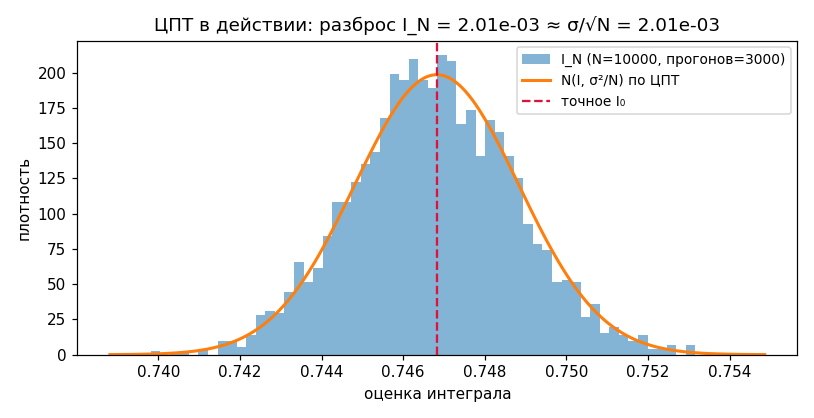

In [ ]:
print(f"{'N':>9} | {'I_N':>13} {'|I_N−I|':>10} {'1.96·s/√N':>10} | {'фактор':>7}")
prev_err = None
for N in [1000, 10000, 100000, 1000000]:
    x = rng.random(N)
    fx = np.exp(-x * x)
    est = fx.mean()
    sd = fx.std(ddof=1)
    err = abs(est - I0)
    factor = '—' if prev_err is None else f'×{prev_err / err:.1f}'
    print(f'{N:9d} | {est:13.9f} {err:10.2e} '
          f'{1.96 * sd / math.sqrt(N):10.2e} | {factor:>7}')
    prev_err = err
print('ошибка падает как 1/√N: ×10 узлов → ×3.2 точности')

# ЦПТ: распределение I_N по повторным прогонам — гауссова плотность
N, reps = 10000, 3000
ests = np.array([np.exp(-rng.random(N) ** 2).mean() for _ in range(reps)])
sigma1 = math.sqrt(J1 - I0 ** 2)        # σ² = ∫e^(-2x²) dx − I0²
fig, ax = plt.subplots(figsize=(7.4, 3.8))
ax.hist(ests, bins=60, density=True, alpha=0.55,
        label=f'I_N (N={N}, прогонов={reps})')
ts = np.linspace(ests.min() - 1e-3, ests.max() + 1e-3, 400)
dens = np.exp(-(ts - I0) ** 2 / (2 * sigma1 ** 2 / N)) /     math.sqrt(2 * math.pi * sigma1 ** 2 / N)
ax.plot(ts, dens, lw=2, label='N(I, σ²/N) по ЦПТ')
ax.axvline(I0, color='crimson', ls='--', lw=1.5, label='точное I₀')
ax.set_xlabel('оценка интеграла'); ax.set_ylabel('плотность')
ax.legend(fontsize=9)
ax.set_title(f'ЦПТ в действии: разброс I_N = {ests.std(ddof=1):.2e} '
             f'≈ σ/√N = {sigma1 / math.sqrt(N):.2e}')
plt.tight_layout(); plt.show()


## 4. 📊 Вероятностный анализ и статистика: доверительные интервалы,
последовательное удвоение, вероятности шара

Статистика добавляет сюда три инструмента.

**1. Выборочная оценка дисперсии.** Дисперсию оцениваем по той же
выборке
($\hat\sigma^2 = \frac{1}{N-1}\sum (f(X_j) - \overline f)^2$,
$\overline f = \frac1N \sum f(X_j)$) — погрешность при этом ставим
$\pm 1.96\,\hat\sigma/\sqrt N$ с вероятностью 95\% (интервал
$[-1.96, 1.96]$ — квантили нормального закона; при больших $N$
поправки на замену параметра оценкой малы).

**2. Алгоритм последовательного удвоения $N$.** Тот же принцип, что в
лекции 9, но оценка погрешности приходит сама собой — с выборочной
дисперсией: начинаем с небольшого $N$, удваиваем до тех пор, пока

$$
\frac{1.96\,\hat\sigma}{\sqrt{N}} > \varepsilon,
\qquad \text{выход из цикла:} \ \frac{1.96\,\hat\sigma}{\sqrt{N}} \le \varepsilon .
$$

Каждое удвоение требует $\tfrac N2$ новых вычислений $f$ — его старые
значения переиспользуются полностью.

**3. Интегралы по плотностям — «ожидания».** Интеграл по мере
вероятности — постоянный источник задач математической статистики:

$$
\mathbb{E}\,g(X) = \int g(x)\,p(x)\,dx,
\qquad P(X \in B) = \int_B p(x)\,dx .
$$

Монте-Карло позволяет вычислять и те, и другие единым образом: при
моделировании $X_j$ из $p$ выборочное среднее $g(X_j)$ несмещённо
оценивает $\mathbb{E}\,g(X)$ (то же доказательство, что в §3).

**Классическая модельная задача: вероятность попадания в шар.** Пусть
$X$ — стандартный $d$-мерный нормальный вектор. Требуется

$$
P_{d,r} = P(\|X\| \le r) = \int_{\|x\| \le r}
\frac{e^{-\|x\|^2/2}}{(2\pi)^{d/2}}\,dx .
$$

Сумма квадратов $\|X\|^2$ распределена как $\chi^2_d$, поэтому при
$t = r^2/2$ вероятность выражается через неполную гамма-функцию:

$$
P_{d,r} = \frac{\gamma(\tfrac{d}{2},\ t)}{\Gamma(\tfrac{d}{2})},
\qquad
\gamma(s, t) = \int_0^t u^{s-1} e^{-u}\,du
= t^s e^{-t} \sum_{k=0}^{\infty} \frac{t^k}{s(s+1)\cdots(s+k)} .
$$

При $d = 2$ есть частный случай ($\chi^2_2$ распределена как
экспоненциальная с масштабом $\tfrac12$):
$P_{2,r} = 1 - e^{-r^2/2}$.
Вычислим точные значения рядом для $r = 1$ и сравним с Монте-Карло
при равном числе точек.

⚠️ **Эффект редких событий.** При больших $d$ и малом $r$ значение $P$
становится крошечным ($P_{10,0.5} \sim 10^{-8}$): чтобы Монте-Карло
«в лоб» его заметило, нужно $N \sim 1/P$ точек — нереально. Выход — §5
(importance sampling) и весь класс «квадратур редких событий».


In [ ]:
def gamma_lower(s, t):
    # ряд γ(s,t) = t^s e^{-t} Σ t^k/(s(s+1)...(s+k)) — сходится при любом s
    total, term, k = 0.0, 1.0 / s, 0
    while True:
        total += term
        if abs(term) < 1e-16 * (abs(total) + 1e-300):
            break
        term *= t / (s + k + 1)
        k += 1
        if k > 5000:
            break
    return t ** s * math.exp(-t) * total

def ball_prob_exact(d, r):
    t = r * r / 2
    return gamma_lower(d / 2, t) / math.gamma(d / 2)

def ball_prob_mc(d, r, N):
    xs = rng.standard_normal((N, d))
    inside = ((xs ** 2).sum(axis=1) <= r ** 2)
    return inside.mean(), inside.std(ddof=1)

r = 1.0
print(f'вероятность попадания в шар радиуса r = {r}')
print(f"{'d':>3} | {'точное γ-рядом':>15} | {'MC N=2e6':>10} "
      f"{'ошибка':>9} {'1.96·s/√N':>10}")
Nmc4 = 2_000_000
for d in [2, 4, 6, 8, 10]:
    Pe = ball_prob_exact(d, r)
    Pm, sd = ball_prob_mc(d, r, Nmc4)
    print(f'{d:3d} | {Pe:15.9f} | {Pm:10.6f} {abs(Pm - Pe):9.2e} '
          f'{1.96 * sd / math.sqrt(Nmc4):10.2e}')
print(f'проверка при d = 2: 1 − e^(-r²/2) = {1 - math.exp(-0.5):.9f} '
      '— совпало с γ-рядом')

# последовательное удвоение N: остановка по stderr ≤ ε
eps = 1e-3
d = 4
print(f'последовательное удвоение N (d = {d}, r = {r}, ε = {eps:.0e}):')
print(f"{'N':>9} | {'1.96·s/√N':>10} {'ошибка факт.':>12}")
fvals = (rng.standard_normal((512, d)) ** 2).sum(axis=1) <= r ** 2
N_total = fvals.size
while True:
    est = fvals.mean()
    sd = fvals.std(ddof=1)
    stderr = 1.96 * sd / math.sqrt(fvals.size)
    print(f'{fvals.size:9d} | {stderr:10.2e} '
          f'{abs(est - ball_prob_exact(d, r)):12.2e}')
    if stderr <= eps:
        break
    half = fvals.size // 2
    new_ch = (rng.standard_normal((half, d)) ** 2).sum(axis=1) <= r ** 2
    fvals = np.concatenate([fvals, new_ch])
    N_total = fvals.size
print(f'остановка на N = {N_total} вычислений f, погрешность ≤ ε '
      '(доверие 95%)')
print('каждое удвоение добавляет лишь N/2 новых вычислений f — как в лекции 9')


вероятность попадания в шар радиуса r = 1.0
  d |  точное γ-рядом |   MC N=2e6    ошибка  1.96·s/√N
  2 |     0.393469340 |   0.393769  2.99e-04   6.77e-04
  4 |     0.090204010 |   0.090584  3.80e-04   3.98e-04
  6 |     0.014387678 |   0.014240  1.47e-04   1.64e-04
  8 |     0.001751623 |   0.001709  4.26e-05   5.72e-05
 10 |     0.000172116 |   0.000158  1.41e-05   1.74e-05
проверка при d = 2: 1 − e^(-r²/2) = 0.393469340 — совпало с γ-рядом
последовательное удвоение N (d = 4, r = 1.0, ε = 1e-03):
        N |  1.96·s/√N ошибка факт.
      512 |   2.38e-02     8.17e-03
      768 |   1.97e-02     5.57e-03
     1152 |   1.63e-02     2.53e-03
     1728 |   1.32e-02     4.56e-03
     2592 |   1.09e-02     3.01e-03
     3888 |   9.07e-03     1.36e-03
     5832 |   7.38e-03     6.74e-04
     8748 |   6.01e-03     2.17e-04
    13122 |   4.91e-03     4.07e-04
    19683 |   4.03e-03     1.25e-03
    29524 |   3.29e-03     1.25e-03
    44286 |   2.68e-03     7.05e-04
    66429 |   2.18e-03     

## 5. ✂️ Снижение дисперсии: antithetic, control variates, importance sampling

Погрешность Монте-Карло $\propto \sigma/\sqrt N$ — значит, конкуренция
за точность идёт **за дисперсию**. Сократить $\sigma$ без потери
несмещённости — классическая практика статистики: три базовых приёма.
Все ведём на сквозном одномерном примере
$I_0 = \int_0^1 e^{-x^2}dx$, чтобы экономия была сравнимой.

**(а) Antithetic variates (сопряжённые переменные).** Если $f$
монотонная, работаем парами: $u$ и $1-u$. Оценка по паре

$$
I_{\text{pair}} = \frac{|\Omega|}{2}\bigl(f(u) + f(1-u)\bigr),\qquad
\mathrm{Var}(I_{\text{pair}}) = \frac{|\Omega|^2\sigma^2}{2}\,(1 + \rho),
$$

где $\rho = \mathrm{Corr}(f(u), f(1-u))$; для строго монотонной $f$
$\rho < 0$ (антикоррелированность), и при $|\rho|$ близком к 1
выигрыш большой. Доказательство — прямая арифметика:
$\mathrm{Var}(A+B) = \mathrm{Var}A + \mathrm{Var}B + 2\,\mathrm{Cov}(A,B)$
и $\mathrm{Cov}(f(u), f(1-u)) = \rho\,\sigma^2$.

**(б) Control variates (контрольные переменные).** Если есть функция
$g$, близкая к $f$, но с известным интегралом $\bar g = \int g$:

$$
I \approx \frac{|\Omega|}{N}\sum_j \bigl(f(X_j) - c\,(g(X_j) - \bar g)\bigr),
\qquad c^* = \frac{\mathrm{Cov}(f, g)}{\mathrm{Var}\,g},
$$

— минимум дисперсии по $c$:
$\mathrm{Var}_{cv} = \sigma_f^2\,(1 - \rho_{fg}^2)$ — тот же механизм,
что коэффициент детерминации в регрессии. Вывод: дифференцируем
$\mathrm{Var}(f - c(g-\bar g)) =
\sigma_f^2 - 2c\,\mathrm{Cov}(f,g) + c^2\,\sigma_g^2$ по $c$ и
приравниваем к нулю.

**(в) Importance sampling (выборка по значимости).** Бросаем не
равномерно, а по плотности $q$, сосредоточенной там, где $|f|$ крупна;
поправка — весами:

$$
I = \int_\Omega f(x)\,dx = \int_\Omega \frac{f(x)}{q(x)}\,q(x)\,dx
= \mathbb{E}_{q}\!\left[\frac{f(X)}{q(X)}\right],
\qquad
I_N^{IS} = \frac{|\Omega|}{N}\sum_j \frac{f(X_j)}{q(X_j)},
$$

— оценка несмещённая для любой плотности $q$ с носителем не уже,
чем у $f$ ($\mathrm{supp}\,q \supseteq \mathrm{supp}\,f$):
$\mathbb{E}_{q}[f/q] = \int (f/q)\,q = \int f$. Дисперсия
$\mathrm{Var}_{q}(f/q)$ минимальна при $q \propto |f|$ — но такая $q$
потребовала бы знать $I$; грубая «поправка направления» уже даёт
большую экономию. На сквозном примере возьмём
$q(x) = e^{-x}/(1 - e^{-1})$ (экспоненциальное уклонение к нулю
интервала — туда, где $f$ крупна; выборка по обратной функции
распределения: $x = -\ln(1 - u(1 - e^{-1}))$, веса $f/q$).

Сравним все четыре оценки при равном $N$.


сравнение дисперсий на I0 = ∫₀¹ e^(-x²) dx, N = 100000:
  plain:            var = 4.036e-02
  antithetic:       var = 8.011e-04  (ρ = -0.960, по формуле σ²(1+ρ)/2 = 8.013e-04)
  control variates: var = 3.021e-03  (c* = +1.0683, ρ_fg = +0.962, σ²(1−ρ²) = 3.021e-03)
  importance s.:    var = 3.031e-03  (оценка 0.746697000, ошибка 1.27e-04)
экономия по дисперсии (тот же N): antithetic ×50, cv ×13, importance ×13


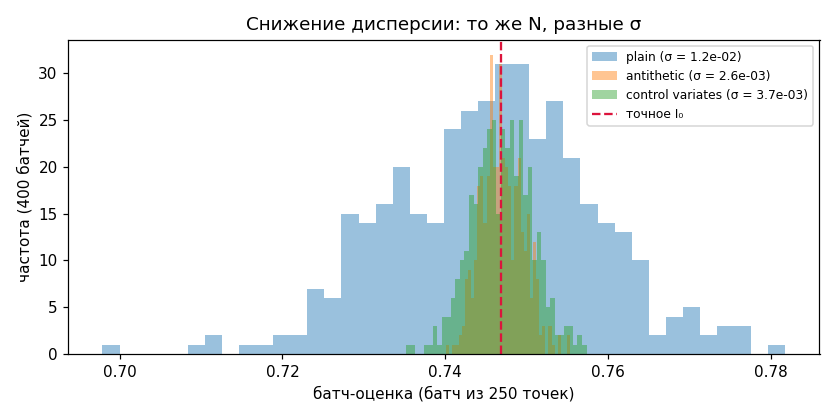

In [ ]:
N = 100_000
u = rng.random(N)

# plain
fx = np.exp(-u * u)
var_plain = fx.var(ddof=1)

# (а) antithetic: пары u и 1-u
ua = rng.random(N // 2)
pair = (np.exp(-ua * ua) + np.exp(-(1 - ua) ** 2)) / 2
var_ant = pair.var(ddof=1)
rho = np.corrcoef(np.exp(-ua * ua), np.exp(-(1 - ua) ** 2))[0, 1]

# (б) control variates: g = e^{-x}, его интеграл 1 − e^{-1} известен
Eg = 1 - math.exp(-1)
gx = np.exp(-u)
c = np.cov(fx, gx, ddof=1)[0, 1] / gx.var(ddof=1)
cv = fx - c * (gx - Eg)
var_cv = cv.var(ddof=1)
rho_fg = np.corrcoef(fx, gx)[0, 1]

# (в) importance sampling: q(x) = e^{-x}/(1−e^{-1}), выборка по обратной ФР
uq = rng.random(N)
xq = -np.log(1 - uq * (1 - math.exp(-1)))
w = np.exp(-xq ** 2) * (1 - math.exp(-1)) / np.exp(-xq)   # f/q
var_is = w.var(ddof=1)
est_is = w.mean()

print(f'сравнение дисперсий на I0 = ∫₀¹ e^(-x²) dx, N = {N}:')
print(f'  plain:            var = {var_plain:.3e}')
print(f'  antithetic:       var = {var_ant:.3e}  (ρ = {rho:+.3f},'
      f' по формуле σ²(1+ρ)/2 = {var_plain * (1 + rho) / 2:.3e})')
print(f'  control variates: var = {var_cv:.3e}  (c* = {c:+.4f},'
      f' ρ_fg = {rho_fg:+.3f}, σ²(1−ρ²) = {var_plain * (1 - rho_fg ** 2):.3e})')
print(f'  importance s.:    var = {var_is:.3e}  (оценка {est_is:.9f},'
      f' ошибка {abs(est_is - I0):.2e})')
print(f'экономия по дисперсии (тот же N): '
      f'antithetic ×{var_plain / var_ant:.0f}, cv ×{var_plain / var_cv:.0f},'
      f' importance ×{var_plain / var_is:.0f}')

# визуализация: разброс батч-оценок (одинаковый размер батча у всех)
def batch_mean(draw, n, m=400):
    return np.array([draw(n).mean() for _ in range(m)])

n_b = 250
plain_batch = batch_mean(lambda k: np.exp(-rng.random(k) ** 2), n_b)

def ant_draw(k):
    uh = rng.random(k // 2)
    return (np.exp(-uh * uh) + np.exp(-(1 - uh) ** 2)) / 2

def cv_draw(k):
    uk = rng.random(k)
    return np.exp(-uk * uk) - c * (np.exp(-uk) - Eg)

ant_batch = batch_mean(ant_draw, n_b)
cv_batch = batch_mean(cv_draw, n_b)

fig, ax = plt.subplots(figsize=(7.6, 3.8))
ax.hist(plain_batch, bins=40, alpha=0.45,
        label=f'plain (σ = {plain_batch.std(ddof=1):.1e})')
ax.hist(ant_batch, bins=40, alpha=0.45,
        label=f'antithetic (σ = {ant_batch.std(ddof=1):.1e})')
ax.hist(cv_batch, bins=40, alpha=0.45,
        label=f'control variates (σ = {cv_batch.std(ddof=1):.1e})')
ax.axvline(I0, color='crimson', ls='--', lw=1.5, label='точное I₀')
ax.set_xlabel('батч-оценка (батч из 250 точек)')
ax.set_ylabel('частота (400 батчей)')
ax.legend(fontsize=8)
ax.set_title('Снижение дисперсии: то же N, разные σ')
plt.tight_layout(); plt.show()


## 6. ⚖️ Кубатура vs Монте-Карло: правила выбора

Соберём всё вместе. Стоимость достижения точности $\varepsilon$ на
кубе $[0,1]^d$:

| | кубатура порядка $p$ | Монте-Карло |
|---|---|---|
| ошибка | $O(N^{-p/d})$ | $O(N^{-1/2})$ |
| узлов для $\varepsilon$ | $N \sim C\,\varepsilon^{-d/p}$ | $N \sim \sigma^2/\varepsilon^2$ |
| рост цены по $d$ | экспоненциальный | не зависит от $d$ |
| область эффективности | гладкая $f$, $d \lesssim 2p$ | любая $d$, любая $f$ с $\mathbb{E}f^2 < \infty$ |

**Правила выбора:**

1. **$d$ мало (до $\sim 2p$), $f$ гладкая** — кубатура с большим
   запасом: при $d = 2$ на $10^4$ узлов тензорный Симпсон даёт ошибку
   ~$10^{-8}$, а Монте-Карло при том же бюджете — ~$2\cdot 10^{-3}$.
2. **$d \gtrsim 6\text{–}10$, $\varepsilon$ грубое** — Монте-Карло
   сразу: сеточным формулам нужны уже триллионы узлов (§2: при $d=10$
   ~$4\cdot 10^{14}$ против ~$10^4$), а МК довольствуется
   $\sim 10^4$.
3. **Гладкости нет** (изломы, разрывы, хаотичные данные) — МК:
   ему не нужна непрерывность, только существование
   $\mathbb{E}f^2 < \infty$.
4. **Редкие события** ($P \ll 1$): МК «в лоб» требует $N \sim 1/P$;
   важно importance sampling (§5) — это его родная среда.
5. **Параллелизм**: точки МК независимы, генерируются без связи друг
   с другом — метод идеально распараллеливается.

Проверим правило «первым числом» на сквозном примере: при равном
бюджете вычислений $f$ ($N = 1024$) сравним тензорное правило (узлов
$n^d \le N$ по оси максимум $n$) и Монте-Карло при росте $d$.


In [ ]:
N_budget = 1024
print(f'равный бюджет вычислений f: N = {N_budget}')
print(f"{'d':>3} | {'узлов куб.':>11} {'|I−T| кубатура':>15} | "
      f"{'|I_N−I| MC':>11} {'1.96·s/√N':>10} | {'победа':>11}")
for d in [1, 2, 4, 6, 8]:
    Iexact = I_of_d(d)
    # кубатура: Симпсон требует нечётного числа узлов по оси (n−1 чётных
    # отрезков); если Симпсон недостижим — midpoint на максимальном n
    n_full = int(math.floor(N_budget ** (1 / d)))
    n = n_full if n_full % 2 == 1 else n_full - 1
    if n >= 3:                            # Симпсон: n узлов, n−1 отрезков
        wv = simpson_weights(n - 1)
        xs = np.linspace(0, 1, n)
        val = (wv @ f0(xs)) ** d          # сепарабельная f
        nodes = n ** d
    elif n_full >= 2:                     # midpoint: n_full узлов по оси
        h = 1 / n_full
        xs = (np.arange(n_full) + 0.5) / n_full   # середины клеток
        val = (h * f0(xs).sum()) ** d
        nodes = n_full ** d
    else:                                 # fallback: центр куба
        val = f0(0.5) ** d
        nodes = 1
    err_cub = abs(val - Iexact)
    # Монте-Карло на полном бюджете
    pts = rng.random((N_budget, d))
    fvals = np.exp(-(pts ** 2).sum(axis=1))
    err_mc = abs(fvals.mean() - Iexact)
    sd = fvals.std(ddof=1)
    verdict = 'кубатура' if err_cub < err_mc else 'Монте-Карло'
    print(f'{d:3d} | {nodes:11d} {err_cub:15.2e} | {err_mc:11.2e} '
          f'{1.96 * sd / math.sqrt(N_budget):10.2e} | {verdict:>11}')
print('порог виден: при малых d кубатура несравнимо точнее, при d ≥ 6–8 '
      'Монте-Карло начинает выигрывать (наклоны −p/d против −1/2)')


равный бюджет вычислений f: N = 1024
  d |  узлов куб.  |I−T| кубатура |  |I_N−I| MC  1.96·s/√N |      победа
  1 |        1023        7.66e-15 |    2.89e-03   1.20e-02 |    кубатура
  2 |         961        1.51e-08 |    1.14e-02   1.33e-02 |    кубатура
  4 |         625        5.21e-05 |    5.57e-05   1.07e-02 |    кубатура
  6 |         729        4.97e-04 |    4.69e-03   7.91e-03 |    кубатура
  8 |         256        8.36e-03 |    3.72e-03   5.23e-03 | Монте-Карло
порог виден: при малых d кубатура несравнимо точнее, при d ≥ 6–8 Монте-Карло начинает выигрывать (наклоны −p/d против −1/2)


## 7. 🧭 Итоги

**Что узнали:**

1. **Кубатурная формула** — та же механика узлов, весов и остаточного
   члена, что в одномерной квадратуре (лекция 9); главный конструктор —
   **тензорное произведение** одномерных правил: ошибка остаётся
   $O(h^p)$, но узлов становится $n^d$.

2. **Проклятие размерности:** из $N \approx h^{-d}$ и
   $|r_T| = O(h^p)$ следует $|r_T| = O(N^{-p/d})$: точность дорожает
   экспоненциально ($N \sim \varepsilon^{-d/p}$); порог
   целесообразности кубатуры: $d \lesssim 2p$.

3. **Монте-Карло:** интеграл $= |\Omega|\,\mathbb{E}f(X)$; оценка
   $I_N$ — **несмещённая**, $\mathrm{Var}\,I_N = |\Omega|^2\sigma^2/N$;
   **закон больших чисел** (через неравенство Чебышёва и Маркова) и
   **центральная предельная теорема** дают рабочую оценку
   $|I_N - I| \approx 1.96\,|\Omega|\,\hat\sigma/\sqrt N$ (95%) —
   ошибка $N^{-1/2}$, не зависящая от $d$.

4. **Статистика:** выборочная $\hat\sigma$, доверительные интервалы,
   алгоритм последовательного удвоения $N$; интегралы по плотностям —
   благодаря той же несмещённости; вероятности редких событий
   требуют сниженной дисперсии (вероятность шара:
   $\gamma(d/2, r^2/2)/\Gamma(d/2)$).

5. **Снижение дисперсии:** antithetic variates
   ($\sigma^2(1+\rho)/2$, на сквозном примере ~×50),
   control variates ($\sigma^2(1-\rho^2)$, ~×13),
   importance sampling ($\mathrm{Var}_q(f/q)$, ~×13); выбор удачной
   $q$ — творческая часть метода.

6. **Правила выбора:** при малых $d$ и гладкой $f$ побеждают
   кубатуры (та же точность дешевле на порядки); при больших $d$,
   негладкой $f$ и редких событиях — Монте-Карло, которому важно
   только существование $\mathbb{E}f^2$, а не гладкость.

**Куда это пойдёт.**
- **Квази-Монте-Карло:** точки из последовательностей Соболя/Холтона
  (low-discrepancy sequences) дают сходимость быстрее $N^{-1/2}$ —
  «детерминистическая версия» стохастического метода.
- **MCMC (Markov chain Monte Carlo):** выборка из сложных плотностей
  (байесовская статистика): Metropolis—Hastings, Gibbs sampling.
- **Importance sampling в машинном обучении:** оценка редких событий и
  «внимания» в моделях; variance reduction в градиентных оценках
  (baseline как control variate).
- **Кубатуры высоких порядков на симплексах:** формулы Радона, кубатуры
  с положительными весами — элемент метода конечных элементов;
  смежные разделы учебника.


# Лекция 10. Теоремы, леммы и доказательства
### (рабочая тетрадь «для доски» — всё строго, по порядку лекции)

**Обозначения.** $\Omega = [0,1]^d$, $|\Omega| = 1$ (объём куба), $d \ge 1$.
$f\colon \Omega \to \mathbb{R}$; для кусочно-гладкой $f$:
$M_p := \max_{k\le d}\ \sup_\Omega \bigl|\partial^p f/\partial x_k^p\bigr|$.
Сквозной пример:
$I_0 = \int_0^1 e^{-x^2}dx = \tfrac{\sqrt\pi}{2}\,\mathrm{erf}(1) = 0.746824132812\ldots$,
$f(x) = e^{-|x|^2}$, $I_d = I_0^d$;
$J_1 = \int_0^1 e^{-2x^2}dx = \sqrt{\pi/8}\,\mathrm{erf}(\sqrt2) = 0.598144007$.
$X$ — равномерная случайная точка $\Omega$; $X_1,\dots,X_N$ — независимые
копии. $\mathbb{E}$, $\mathrm{Var}$, $\mathrm{Cov}$ — математическое ожидание,
дисперсия, ковариация.

---

## 0. Словарь обозначений (читать перед теоремами)

| Символ | Что означает |
|---|---|
| $[0,1]^d$ | $d$-мерный куб: наборы чисел $0\le x_1\le1,\ \dots,\ 0\le x_d\le1$ (при $d=2$ это просто квадрат) |
| $\Omega$, $|\Omega|$ | область интегрирования и её объём; у куба объём $= 1$ |
| $N$ | число вычислений функции $f$ (число узлов сетки или случайных точек) |
| $\partial^p_{x_k} f$ | частная производная порядка $p$ по переменной номер $k$; остальные переменные при дифференцировании фиксируются («заморожены») |
| $\sup$ | точная верхняя грань (максимум для непрерывной функции на замкнутом отрезке/кубе) |
| $\lceil x\rceil$ | округление вверх до целого («потолок») |
| $\mathbb{E}$, $\mathrm{Var}$, $\mathrm{Cov}$ | математическое ожидание, дисперсия, ковариация |
| $\sigma$, $\hat\sigma$ | стандартное отклонение; «сигма с крышкой» — её оценка по выборке (теорема 4.1) |
| $U[0,1]$ | равномерное распределение на отрезке (плотность постоянна, равна 1) |
| $\mathcal{N}(0,1)$ | стандартное нормальное распределение (колокольчик с дисперсией 1) |
| $\Phi$, $\varphi$ | функция распределения и плотность стандартного нормального закона |
| $\Rightarrow$ | сходимость распределений; $\xrightarrow[N\to\infty]{ }$ — переход к пределу по $N$ |
| $\Gamma(s)$ | гамма-функция — обобщение факториала: $\Gamma(n) = (n-1)!$ для целых $n$ |
| $\gamma(s,t)$ | неполная гамма-функция: тот же интеграл, но от 0 до $t$ (теорема 4.6) |
| $(s)_k$ | возрастающий факториал: $s(s+1)\cdots(s+k)$ |
| $\chi^2_d$ | распределение суммы квадратов $d$ независимых стандартных нормалей |
| $\sim$ | «распределена как»: $Y \sim \chi^2_d$ значит $Y$ имеет распределение $\chi^2_d$ |
| $\propto$ | «пропорционально»: $q\propto f$ значит $q = c\cdot f$ с каким-то множителем $c$ |

**Слово «тензор» здесь не про алгебру.** Никаких объектов-тензоров из
курса линейной алгебры не понадобится. «Тензорное произведение правил» —
это просто название приёма: **одно и то же одномерное правило применяется
к каждой оси куба**, а полученные узлы комбинируются «все со всеми»
(полный разбор — в п. 1.2а).

---

## 1. Кубатурные формулы

**Определение 1.1 (кубатурная формула).** Приближённое равенство
$$
I = \int_\Omega f(x)\,dx \approx \sum_{j} A_j\, f(x_j),
$$
где $x_j \in \Omega$ — **узлы**, $A_j$ — **веса**; функционал
$Q f = \sum_j A_j f(x_j)$ называется кубатурным (при $d=1$ — квадратурным)
оператором, а $r = If - Qf$ — **остаточным членом**.

**Определение 1.2 (тензорное произведение правил).** Пусть на $[0,1]$ задано
одномерное правило с узлами $\xi_0,\dots,\xi_n$ и весами $w_0,\dots,w_n$,
$q(x) \mapsto \sum_{s} w_s\, q(\xi_s)$. Разобьём $[0,1]^d$ сеткой с шагом
$h = 1/n$ по каждой оси; **тензорное правило**
$$
T_d f = \sum_{s_1=0}^{n}\cdots\sum_{s_d=0}^{n}
w_{s_1}\cdots w_{s_d}\, f(\xi_{s_1},\dots,\xi_{s_d})
$$
суммирует узлы полной сетки с произведениями весов; их число
$N = K^d$, где $K$ — число узлов правила по одной оси ($K = n+1$ у
Симпсона/трапеций, $K = n$ у средней точки); всюду ниже просто
$N \approx n^d$.

Введём линейные операторы, действующие каждый на свою переменную:
$\mathcal{J}$ — интегрирование по одной оси (при фиксированных остальных),
$Q$ — одномерное квадратурное правило по той же оси. Тогда
$$
I_d f = (\mathcal{J}^{\otimes d}) f, \qquad T_d f = (Q^{\otimes d}) f,
$$
и операторы, действующие на **разные** переменные, коммутируют.

**Разбор 1.2а. Тензорное правило по шагам (на примере $d = 2$).**
При $d = 2$ куб $[0,1]^2$ — это обычный квадрат на плоскости с
координатами $(x, y)$; «сетка с шагом $h = 1/n$ по каждой оси» делит
его на квадратные клетки, узлы которых образуют таблицу
$(n+1)\times(n+1)$ точек.

**Шаг 1. Одномерное правило — это список узлов и весов.** Например,
правило средней точки с $n = 2$ (две половинные клетки):
$$
\xi_0 = 0.25,\ \xi_1 = 0.75; \qquad w_0 = w_1 = \tfrac12;
\qquad \sum_s w_s = 1 .
$$

**Шаг 2. Интегрируем по первой оси.** Зафиксируем $y$. Функция
$x \mapsto f(x, y)$ — обычная функция одного переменного; применяем к
ней одномерное правило:
$$
\int_0^1 f(x, y)\,dx \ \approx\ \sum_{i=0}^{1} w_i\, f(\xi_i, y).
$$

**Шаг 3. Интегрируем результат по второй оси.** Полученный ответ зависит
от $y$ — применяем тот же шаблон к функции $y \mapsto \sum_i w_i
f(\xi_i, y)$:
$$
\int_0^1\!\Bigl(\sum_i w_i f(\xi_i, y)\Bigr)dy
\ \approx\ \sum_{j=0}^{1} w_j \sum_{i=0}^{1} w_i\, f(\xi_i, \xi_j).
$$

**Шаг 4. Раскрываем вложенную сумму.** Числа $w_i$ выносятся наружу:
$$
T_2 f = \sum_{i,j} \underbrace{w_i\,w_j}_{\text{произведение весов}}\,
f(\xi_i, \xi_j).
$$
Узлы — все пары (комбинации) одномерных узлов: в примере их
$2^2 = 4$. В общем виде число узлов такое: $K^d$, где $K$ — число узлов
одномерного правила по одной оси ($K = n+1$ у Симпсона и трапеций — узлы
на концах клеток, $K = n$ у средней точки — по одному узлу на клетку).
Дальше везде пишем просто «$\approx n^d$», потому что разница
между $K$ и $n$ не меняет экспоненциального роста по $d$.

**Числовой пример к шагам 1–4** ($f(x,y) = e^{-x^2-y^2}$, наше $f$ при
$d = 2$). Узлы и значения:
$$
f(0.25, 0.25) = e^{-0.125} = 0.882497,\quad
f(0.25, 0.75) = f(0.75, 0.25) = e^{-0.625} = 0.535261,
$$
$$
f(0.75, 0.75) = e^{-1.125} = 0.324653;
\qquad
T_2 = \tfrac14\,(0.882497 + 2\cdot 0.535261 + 0.324653) = 0.569418 .
$$
Точное значение $I_2 = I_0^2 = 0.557746$; ошибка $0.0117$, и граница
теоремы 1.6 обещает не хуже
$\tfrac{d\,M_2h^2}{24} = \tfrac{2\cdot2\cdot(1/2)^2}{24} = \tfrac1{48}
\approx 0.0208$ — всё сходится.

**Как читать записи с $\otimes$ (без «настоящих» тензоров).**
$\mathcal{J}$ — сокращение для «проинтегрируй по своей оси»;
$\mathcal{J}^{\otimes d} f$ — просто «проинтегрируй по всем $d$ осям
подряд» (кратная запись повторного интеграла); $Q^{\otimes d} f$ —
«примени правило по каждой оси». Коммутативность операторов на разных
осях — это равенство повторных интегралов (теорема Фубини для
непрерывных функций на кубе): интегрирование по $x$ не мешает
интегрированию по $y$.

**Как читать телескопическую сумму из леммы 1.3.** Разница «всё точно
минус всё приближённо» разбивается по числу осей, на которых правило
$Q$ уже заменяет точный интеграл:
$$
\underbrace{\mathcal{J}\otimes\dots\otimes\mathcal{J}}_{\text{всё точно}}
\;-\;
\underbrace{Q\otimes\dots\otimes Q}_{\text{всё правило}}
= \sum_{k=1}^{d}
\Bigl(\underbrace{Q\otimes\dots\otimes Q}_{k-1\ \text{осей}}\Bigr)
\otimes \underbrace{(\mathcal{J}-Q)}_{k\text{-я ось: остаток}}
\otimes
\Bigl(\underbrace{\mathcal{J}\otimes\dots\otimes\mathcal{J}}_{\text{остальные точные}}\Bigr).
$$
Каждое слагаемое говорит: «на одной оси накопилась остаточная
погрешность, предыдущие оси уже считались правилом, следующие ещё
считаются точно». Теорема 1.6 оценивает такое слагаемое и складывает $d$
одинаковых вкладов — отсюда множитель $d$ в оценках.


**Лемма 1.3 (телескопическое тождество).** Для любых линейных операторов
$A, B$ и любого $d \ge 1$
$$
A^{\otimes d} - B^{\otimes d}
= \sum_{k=1}^{d} B^{\otimes(k-1)} \otimes (A-B) \otimes A^{\otimes(d-k)}.
$$

*Доказательство.* Индукция по $d$. База $d=1$ пуста (сумма из одного
слагаемого $A-B$). Переход $d \to d+1$: по оси $d+1$ имеем два варианта
последнего фактора, поэтому
$$
A^{\otimes(d+1)} - B^{\otimes(d+1)}
= \bigl(A^{\otimes d} - B^{\otimes d}\bigr)\otimes A
+ B^{\otimes d}\otimes (A-B).
$$
Подставляя индукционное допущение в первую скобку:
$$
\Bigl[\sum_{k=1}^{d} B^{\otimes(k-1)}\otimes(A-B)\otimes A^{\otimes(d-k)}\Bigr]\otimes A
+ B^{\otimes d}\otimes(A-B),
$$
— правая часть леммы при $d+1$. $\blacksquare$

Применяем лемму к $A = \mathcal{J}$, $B = Q$; обозначим одномерный
остаточный член $\mathcal{R} = \mathcal{J} - Q$.

**Лемма 1.4 (норма правила с неотрицательными весами).** Если все $w_s \ge 0$
и $\sum_s w_s = 1$ (например, правило средней точки или Симпсона на
$[0,1]$), то для любой ограниченной $g$
$$
|Qg| \le \sup |g|, \qquad |\mathcal{J}g| \le \sup |g| \quad (|\Omega|=1).
$$

*Доказательство.* $|Qg| = \bigl|\sum w_s g(\xi_s)\bigr| \le \sum w_s \sup|g| = \sup|g|$.
Интеграл: $\bigl|\int_0^1 g\,dx\bigr| \le \int_0^1 \sup|g|\,dx = \sup|g|$.
$\blacksquare$

**Лемма 1.5 (одномерный остаточный член средней точки).** Если $g''$
непрерывна на клетке $[a, a+h]$, то для правила средней точки
$$
\Bigl|\int_a^{a+h} g(x)\,dx - h\, g\bigl(a+\tfrac h2\bigr)\Bigr|
\le \frac{h^3}{24}\sup_{[a,a+h]}|g''|.
$$

*Доказательство.* По формуле Тейлора с центром в середине клетки
$\xi = a + h/2$ и остатком в форме Лагранжа: для каждого $x$ существует
$\zeta_x$ между $x$ и $\xi$:
$g(x) = g(\xi) + g'(\xi)(x-\xi) + \tfrac12 g''(\zeta_x)(x-\xi)^2$.
Интегрируем по клетке: $\int_a^{a+h}(x-\xi)\,dx = 0$ (симметрия), поэтому
$$
\Bigl|\int_a^{a+h} g\,dx - h\,g(\xi)\Bigr|
\le \frac12 \sup|g''| \int_a^{a+h} (x-\xi)^2 dx
= \frac12 \sup|g''|\cdot\frac{h^3}{12} = \frac{h^3}{24}\sup|g''|.
$$
$\blacksquare$

**Теорема 1.6 (остаточный член тензорного правила).** Пусть одномерное
правило с неотрицательными весами суммы 1 имеет на каждой клетке шага $h$
остаток $|\mathcal{R}_{\text{лок}} g| \le C\, h^{p}\, \sup|g^{(p)}|$
(для средней точки $p=2$, $C = \tfrac1{24}$ — лемма 1.5). Если
$M_p = \max_k \sup_\Omega |\partial^p_{x_k} f| < \infty$, то
$$
|r_T| = \bigl|I_d f - T_d f\bigr| \le d\, C\, M_p\, h^{p}.
$$

*Доказательство.* По лемме 1.3
$$
r_T f = \sum_{k=1}^{d}
\bigl(Q^{\otimes(k-1)} \otimes \mathcal{R} \otimes \mathcal{J}^{\otimes(d-k)}\bigr) f .
$$
Рассмотрим $k$-е слагаемое. Действие $\mathcal{R}$ по оси $k$ на функцию
с зафиксированными остальными координатами $y$ (линейность остатка) даёт
$$
\bigl|\mathcal{R}\, f(\cdot, y)\bigr|
\le C\, h^{p} \sup_{x_k} \bigl|\partial^p_{x_k} f(x_k, y)\bigr|
\le C\, h^{p} M_p .
$$
Далее по лемме 1.4 операторы $Q$ и $\mathcal{J}$ (неотрицательные веса
с суммой 1; интеграл по кубу объёма 1) не увеличивают sup, поэтому каждое
слагаемое по модулю не превосходит $C\,h^p M_p$, а сумма $d$ слагаемых —
$d\,C\,M_p\,h^p$. $\blacksquare$


**Следствие 1.7 (бюджет узлов).** Чтобы обеспечить $|r_T| \le \varepsilon$
правилом средней точки, достаточно
$$
h \le \sqrt{24\varepsilon/(d\,M_2)}
\quad\Longrightarrow\quad
n \ge \Bigl\lceil \sqrt{d\,M_2/(24\varepsilon)} \Bigr\rceil
$$
отрезков по каждой оси, узлов $N \approx n^d$. Для сквозного примера
($M_2 = 2$, $\varepsilon = 10^{-3}$):
$n_d = \lceil\sqrt{d/(12\varepsilon)}\rceil$; при $d = 10$: $n_d = 29$,
узлов $29^{10} \approx 4.21\cdot 10^{14}$.

**Замечание (гладкость).** Оценки лемм 1.5–1.6 требуют непрерывных частных
производных до порядка $p$ включительно. На изломах порядковая скорость
теряется — та же картина, что в лекции 9.

---

## 2. Проклятие размерности

**Теорема 2.1 (главное соотношение размерности).** Пусть выполнены условия
теоремы 1.6, сетка изотропна: $n$ отрезков по каждой оси. Тогда
$N \approx h^{-d}$ и
$$
|r_T| = O(N^{-p/d}), \qquad\text{стоимость точности } \varepsilon:\quad
N \sim \varepsilon^{-d/p}.
$$

*Доказательство.* Подстановка $h = N^{-1/d}$ в $|r_T| \le dCM_ph^p$ даёт
$|r_T| \le dCM_p\,N^{-p/d}$. Обратно: чтобы $|r_T| \le \varepsilon$, нужно
$h^p \le \varepsilon/(dCM_p)$, т.е.
$N = h^{-d} \ge (dCM_p/\varepsilon)^{d/p}$ — экспонента по $d$ в
показателе $d/p$. $\blacksquare$

**Лемма 2.2 (дисперсия сквозного примера).** Для $f(x) = e^{-|x|^2}$ на
$[0,1]^d$, $X$ — равномерная на кубе:
$$
\sigma_d^2 := \mathrm{Var}\, f(X) = J_1^{\,d} - I_0^{\,2d}.
$$
Значения: $\sigma_1 = 0.2010$, $\sigma_2 = 0.2161$, $\sigma_4 = 0.1767$,
$\sigma_6 = 0.1253$, $\sigma_8 = 0.0838$, $\sigma_{10} = 0.0543$.

*Доказательство.* $\mathrm{Var} = \mathbb{E}f^2 - (\mathbb{E}f)^2$.
Сепарабельность даёт
$\mathbb{E}f^2 = \int_{[0,1]^d} e^{-2|x|^2} dx
= \bigl(\int_0^1 e^{-2t^2}dt\bigr)^d = J_1^d$, а
$\mathbb{E}f = I_0^d$. $\blacksquare$

**Теорема 2.3 (порог $d \lesssim 2p$).** Кубатура порядка $p$ требует
$N_{\text{куб}} \sim \varepsilon^{-d/p}$ вычислений $f$; Монте-Карло
(следствие 3.9) — $N_{\text{МК}} \approx (1.96\,\sigma_d/\varepsilon)^2
\sim \varepsilon^{-2}$. При малых $\varepsilon$ выигрывает та, у которой
меньше показатель степени: кубатура дешевле при $d/p < 2$, т.е.
$$
d < 2p,
$$
и дороже при $d > 2p$. Для правил порядка 2 порог $d > 4$; для Симпсона
($p = 4$) порог $d > 8$.

*Доказательство.* Сравнение показателей $\varepsilon^{-d/p}$ и
$\varepsilon^{-2}$: при $\varepsilon \to 0$ меньший показатель даёт
экспоненциально меньшее число вычислений; множители ($1.96\sigma_d$ и
$dCM_p$) на порог не влияют — лишь сдвигают точку пересечения по
$\varepsilon$. $\blacksquare$

---

## 3. Монте-Карло: четыре столпа

**Определение 3.1.** $X$ — равномерная на $\Omega$ случайная точка
(плотность $1/|\Omega|$). **Оценкой Монте-Карло** интеграла называется
$$
I_N := \frac{|\Omega|}{N}\sum_{j=1}^{N} f(X_j), \qquad
X_1,\dots,X_N\ \text{независимы, распределены как } X .
$$

**Лемма 3.2 (интеграл как ожидание).**
$$
\mathbb{E}\, f(X) = \frac{1}{|\Omega|}\int_\Omega f(x)\,dx,
\qquad\text{т.е.}\qquad I = |\Omega|\;\mathbb{E}\, f(X).
$$

*Доказательство.* По определению ожидания для абсолютно непрерывного
закона $\mathbb{E}\,f(X) = \int_\Omega f(x)\,p(x)\,dx$ с плотностью
$p = 1/|\Omega|$. $\blacksquare$

**Теорема 3.3 (несмещённость).** $\mathbb{E}\,I_N = I$.

*Доказательство.* Ожидание линейно, $X_j$ распределены одинаково:
$$
\mathbb{E}\, I_N = \frac{|\Omega|}{N}\sum_{j=1}^{N} \mathbb{E}\, f(X_j)
= \frac{|\Omega|}{N}\cdot N\,\mathbb{E}\,f(X) = I
\quad\text{(лемма 3.2).} \blacksquare
$$

**Теорема 3.4 (дисперсия оценки).** Если $\sigma^2 = \mathrm{Var}\, f(X) < \infty$, то
$$
\mathrm{Var}\, I_N = \frac{|\Omega|^2\sigma^2}{N}.
$$

*Доказательство.* Независимость $X_j$ обнуляет ковариации, поэтому
$\mathrm{Var}\bigl(\sum_j f(X_j)\bigr) = \sum_j \mathrm{Var}\,f(X_j) =
N\sigma^2$. Умножение на константу $c = |\Omega|/N$ даёт множитель
$c^2$:
$$
\mathrm{Var}\,I_N = \frac{|\Omega|^2}{N^2}\cdot N\sigma^2
= \frac{|\Omega|^2\sigma^2}{N}. \blacksquare
$$

**Лемма 3.5 (неравенство Маркова).** Для любой случайной величины $Y$ и
любого $t > 0$
$$
P(|Y| \ge t) \le \frac{\mathbb{E}\,Y^2}{t^2}.
$$

*Доказательство.* Разбиение события (ограниченность $y^2 < t^2$ на
$\{|y| < t\}$):
$$
\mathbb{E}Y^2 = \int_{|y|<t} y^2\,dP + \int_{|y|\ge t} y^2\,dP
\ \ge\ \int_{|y|\ge t} y^2\,dP \ \ge\ t^2\,P(|Y|\ge t).
$$
$\blacksquare$

**Лемма 3.6 (неравенство Чебышёва).** Если $\mathbb{E}Y^2 < \infty$, то
для любого $\varepsilon > 0$
$$
P\bigl(|Y - \mathbb{E}Y| \ge \varepsilon\bigr)
\le \frac{\mathrm{Var}\,Y}{\varepsilon^2}.
$$

*Доказательство.* Применим лемму 3.5 к центрированной величине
$Z = Y - \mathbb{E}Y$: при $\mathbb{E}Z = 0$ имеем
$\mathbb{E}Z^2 = \mathrm{Var}\,Z$, откуда
$P(|Y-\mathbb{E}Y|\ge\varepsilon) \le \mathrm{Var}\,Y/\varepsilon^2$.
$\blacksquare$

**Теорема 3.7 (закон больших чисел для $I_N$).** Для любого
$\varepsilon > 0$
$$
P\bigl(|I_N - I| \ge \varepsilon\bigr)
\le \frac{|\Omega|^2\sigma^2}{N\,\varepsilon^2}
\ \xrightarrow[N\to\infty]{}\ 0 .
$$

*Доказательство.* Возьмём $Y = I_N - I$. По теореме 3.3
$\mathbb{E}Y = 0$; по теореме 3.4 $\mathrm{Var}\,Y = |\Omega|^2\sigma^2/N$.
Подстановка в лемму 3.6. $\blacksquare$

**Теорема 3.8 (центральная предельная теорема; формулировка).** Если
$\sigma^2 < \infty$, то распределение нормированной ошибки
$$
Z_N = \frac{\sqrt{N}\,\bigl(I_N - I\bigr)}{|\Omega|\,\sigma}
$$
сходится к стандартному нормальному: $Z_N \Rightarrow \mathcal{N}(0,1)$.
Доказательство (через характеристические функции, метод Ляпунова) есть в
любом курсе теории вероятностей; здесь мы на него опираемся и
подтверждаем результат гистограммой повторных прогонов (ноутбук §3).

**Следствие 3.9 (рабочая оценка погрешности, 95%).**
$$
P\Bigl(|I_N - I| \le 1.96\,\frac{|\Omega|\,\sigma}{\sqrt N}\Bigr)
\ \approx\ P(|Z| \le 1.96) = 2\Phi(1.96) - 1 = 0.9500\ldots
$$

*Доказательство.* По теореме 3.8 распределение $Z_N$ близко к
$\mathcal{N}(0,1)$; $1.96$ — 97.5%-квантиль нормального закона
($\Phi(1.96) = 0.975002\ldots$); по симметрии
$P(|Z|\le 1.96) = 2\Phi(1.96)-1$. $\blacksquare$

**Замечание (замена $\sigma$ на $\hat\sigma$).** На практике $\sigma$
неизвестна, но состоятельно оценивается по той же выборке (теорема 4.1);
при больших $N$ подстановка оценки в квантиль не меняет выводов. Так
возникает формула $|I_N - I| \approx 1.96\,|\Omega|\,\hat\sigma/\sqrt N$.

---

## 4. Статистика: выборочная дисперсия, удвоение, вероятности шара

**Теорема 4.1 (несмещённость выборочной дисперсии).** Пусть
$X_1,\dots,X_N$ независимы, $\mathbb{E}X_j = \mu$,
$\mathrm{Var}\,X_j = \sigma^2 < \infty$, $\overline X = \frac1N\sum X_j$.
Тогда
$$
\hat\sigma^2 := \frac{1}{N-1}\sum_{j=1}^{N}(X_j - \overline X)^2,
\qquad \mathbb{E}\,\hat\sigma^2 = \sigma^2 .
$$

*Доказательство.* Алгебраическое тождество: раскрываем
$\sum_j (X_j - \overline X)^2$ через $\mu$:
$$
\sum_j (X_j - \overline X)^2
= \sum_j (X_j-\mu)^2 - 2(\overline X-\mu)\sum_j (X_j-\mu)
+ N(\overline X-\mu)^2.
$$
Так как $\sum_j (X_j-\mu) = N(\overline X - \mu)$, среднее слагаемое
равно $-2N(\overline X-\mu)^2$, итого
$$
\sum_j (X_j-\overline X)^2 = \sum_j (X_j-\mu)^2 - N(\overline X-\mu)^2 .
$$
Берём ожидания: $\mathbb{E}\sum_j(X_j-\mu)^2 = N\sigma^2$;
$\mathbb{E}(\overline X-\mu)^2 = \mathrm{Var}\,\overline X = \sigma^2/N$
(теорема 3.4 для $f = \mathrm{id}$, $|\Omega|=1$). Итого
$$
\mathbb{E}\sum_j (X_j-\overline X)^2
= N\sigma^2 - N\cdot\frac{\sigma^2}{N} = (N-1)\sigma^2,
\qquad \mathbb{E}\,\hat\sigma^2 = \sigma^2. \blacksquare
$$

**Алгоритм 4.2 (последовательное удвоение $N$).** Стартуем с $N_0$; имея
выборку $f(X_1),\dots,f(X_N)$, считаем $\hat\sigma$ и критерий
$\frac{1.96\,\hat\sigma}{\sqrt N} \le \varepsilon$; если он не выполнен,
добавляем $N/2$ новых точек (все старые значения $f$ переиспользуются)
и повторяем. Остановка даёт $\approx 95\%$-доверие к
$|I_N - I| \le \varepsilon$ (следствие 3.9). На задаче о шаре
($d = 4$, $r = 1$, $\varepsilon = 10^{-3}$) остановка при
$N = 336\,294$.

Дальше — вычисление $P_{d,r} = P(\|X\|\le r)$ для стандартного
$d$-мерного нормального вектора $X$ (плотность
$(2\pi)^{-d/2}e^{-|x|^2/2}$).

**Лемма 4.3 (квадрат координаты).** Если $Z \sim \mathcal{N}(0,1)$, то
$U = Z^2$ имеет плотность
$$
p_U(u) = \frac{1}{\sqrt{2\pi}}\,u^{-1/2}\,e^{-u/2}, \qquad u > 0 .
$$

*Доказательство.* Для $u > 0$:
$F_U(u) = P(Z^2 \le u) = P(-\sqrt u \le Z \le \sqrt u)
= 2\Phi(\sqrt u) - 1$. Дифференцируем:
$$
p_U(u) = 2\,\varphi(\sqrt u)\cdot\frac{1}{2\sqrt u}
= \varphi(\sqrt u)\,u^{-1/2}
= \frac{1}{\sqrt{2\pi}}\,u^{-1/2}e^{-u/2}. \blacksquare
$$

**Лемма 4.4 (свёртка гамма-распределений).** Если $A \sim \Gamma(a,\theta)$
и $B \sim \Gamma(b,\theta)$ независимы (плотности
$x^{a-1}e^{-x/\theta}/(\Gamma(a)\theta^a)$ и аналогично), то
$A+B \sim \Gamma(a+b,\theta)$.

*Доказательство.* Свёртка плотностей (независимость):
$$
p_{A+B}(u) = \int_0^u
\frac{x^{a-1}e^{-x/\theta}}{\Gamma(a)\theta^a}\cdot
\frac{(u-x)^{b-1}e^{-(u-x)/\theta}}{\Gamma(b)\theta^b}\,dx
$$
$$
= \frac{e^{-u/\theta}}{\Gamma(a)\Gamma(b)\theta^{a+b}}
\int_0^u x^{a-1}(u-x)^{b-1}\,dx .
$$
Замена $x = ut$, $dx = u\,dt$:
$\int_0^u x^{a-1}(u-x)^{b-1}dx = u^{a+b-1}\int_0^1 t^{a-1}(1-t)^{b-1}dt
= u^{a+b-1}\,\mathrm{B}(a,b)$, где $\mathrm{B}(a,b) =
\Gamma(a)\Gamma(b)/\Gamma(a+b)$ — бета-интеграл Эйлера (стандартный факт
анализа). Итого
$$
p_{A+B}(u) = \frac{e^{-u/\theta}u^{a+b-1}}{\Gamma(a+b)\theta^{a+b}} —
\text{ плотность } \Gamma(a+b,\theta). \blacksquare
$$

**Теорема 4.5 (сумма квадратов распределена как $\chi^2_d$).** Для
стандартного нормального вектора $X$
$$
\|X\|^2 \sim \chi^2_d \equiv \Gamma\bigl(\tfrac d2,\ 2\bigr),
\qquad
p(u) = \frac{u^{d/2-1}e^{-u/2}}{2^{d/2}\Gamma(d/2)},\ u > 0 .
$$

*Доказательство.* По лемме 4.3 каждая $X_j^2 \sim \Gamma(\tfrac12, 2)$:
плотности совпадают, так как $u^{-1/2} = u^{1/2-1}$ и
$\Gamma(\tfrac12)\,2^{1/2} = \sqrt{\pi}\sqrt2$, т.е.
$(\Gamma(1/2)\,2^{1/2})^{-1} = (2\pi)^{-1/2}$. Координаты независимы, и
по лемме 4.4 (индукция по числу слагаемых) сумма $d$ штук имеет
распределение $\Gamma(\tfrac d2, 2)$. $\blacksquare$

**Теорема 4.6 (гамма-формула вероятности шара).**
$$
P_{d,r} = P(\|X\| \le r)
= \frac{\gamma\bigl(\tfrac d2,\ \tfrac{r^2}2\bigr)}{\Gamma(\tfrac d2)},
\qquad \gamma(s,t) := \int_0^t u^{s-1}e^{-u}\,du .
$$

*Доказательство.* По теореме 4.5 событие $\{\|X\|\le r\}$ — это
$\{U \le r^2\}$ для $U = \|X\|^2 \sim \Gamma(d/2,2)$:
$$
P_{d,r} = \int_0^{r^2} \frac{u^{d/2-1}e^{-u/2}}{2^{d/2}\Gamma(d/2)}\,du .
$$
Замена $u = 2t$, $du = 2\,dt$:
$$
P_{d,r} = \int_0^{r^2/2}
\frac{(2t)^{d/2-1}e^{-t}}{2^{d/2}\Gamma(d/2)}\,2\,dt
= \int_0^{r^2/2} \frac{t^{d/2-1}e^{-t}}{\Gamma(d/2)}\,dt
= \frac{\gamma(d/2,\,r^2/2)}{\Gamma(d/2)}. \blacksquare
$$

**Частный случай $d = 2$.** $\gamma(1,t) = 1-e^{-t}$, поэтому
$P_{2,r} = 1 - e^{-r^2/2}$; численно $P_{2,1} = 0.393469340$ — совпадает
с γ-рядом. Таблица точных значений при $r = 1$:
$d=2$: 0.393469340; $d=4$: 0.090204010; $d=6$: 0.014387678;
$d=8$: 0.001751623; $d=10$: 0.000172116.

**Теорема 4.7 (ряд для неполной гаммы).** При $s > 0$, $t \ge 0$
$$
\gamma(s,t) = t^s e^{-t}\sum_{k=0}^{\infty}
\frac{t^k}{s(s+1)\cdots(s+k)} .
$$

*Доказательство.* Положим $(s)_0 := 1$,
$(s)_{k+1} := s(s+1)\cdots(s+k)$ и
$$
F(s,t) := t^s e^{-t}\sum_{k=0}^{\infty}\frac{t^k}{(s)_{k+1}} .
$$
Ряд и его почленные производные сходятся равномерно на каждом отрезке
$t \in [0,T]$ ($k$-й член имеет мажоранту порядка $T^{s+k}(s+k+2)/((s)_{k+1})\,
e^{-0}$, которая по факториальному росту $(s)_{k+1} \sim k!\cdot k^{s}$
суммируемая), поэтому дифференцируем почленно:
$$
\frac{\partial}{\partial t}\bigl[t^{s+k}e^{-t}\bigr]
= t^{s+k-1}e^{-t}\bigl[(s+k) - t\bigr],
$$
и, делённое на $(s)_{k+1}$,
$$
F'(s,t) = t^{s-1}e^{-t}\sum_{k=0}^{\infty}\left(
\frac{t^k(s+k)}{(s)_{k+1}} - \frac{t^{k+1}}{(s)_{k+1}}\right)
= t^{s-1}e^{-t}\sum_{k=0}^{\infty}\left(
\frac{t^k}{(s)_k} - \frac{t^{k+1}}{(s)_{k+1}}\right),
$$
где использовано $\frac{s+k}{(s)_{k+1}} = \frac{1}{(s)_k}$. Сумма —
телескопическая: промежуточные члены сокращаются, остаётся
$1/(s)_0 = 1$:
$$
F'(s,t) = t^{s-1}e^{-t}.
$$
Кроме того $F(s,0) = 0$. Значит $F(s,t) = \int_0^t u^{s-1}e^{-u}du =
\gamma(s,t)$ (обе функции начинаются с нуля и имеют одну производную).
$\blacksquare$

*Проверка:* $s = 1$: ряд даёт
$t e^{-t}\sum t^k/(k+1)! = te^{-t}\cdot\frac{e^t - 1}{t} = 1 - e^{-t}
= \gamma(1,t)$ ✓; при $d = 2$ ($s = 1$):
$P_{2,1} = 1 - e^{-1/2} = 0.393469340$ ✓.

**Теорема 4.8 (стоимость редких событий).** Пусть событие имеет малую
вероятность $p \ll 1$, и по выборке объёма $N$ считается доля попаданий
$\hat p$. Чтобы относительная погрешность доли была не хуже $\delta$
(по ЦПТ, с вероятностью 95%), нужно
$$
N \ \gtrsim\ \frac{1-p}{p\,\delta^2}\ \approx\ \frac{1}{p\,\delta^2},
$$
т.е. при фиксированной относительной точности стоимость растёт как
$1/p$: «в лоб» Монте-Карло для $P \sim 10^{-8}$ требует $N \sim 10^8$
и более.

*Доказательство.* Доля попаданий — среднее индикаторов;
$\mathrm{Var}\,\hat p = p(1-p)/N$ (теорема 3.4 для берниевских
$X_j$, $\sigma^2 = p(1-p)$, $|\Omega| = 1$). По следствию 3.9 рабочий
интервал $\hat p \pm 1.96\sqrt{p(1-p)/N}$; относительная ошибка
$1.96\sqrt{p(1-p)/N}/p \approx 1.96\sqrt{(1-p)/(pN)}$; требование
$\le \delta$ даёт $N \ge 1.96^2 (1-p)/(p\delta^2)$. $\blacksquare$

---

## 5. Снижение дисперсии

Пусть $|\Omega| = 1$, $\sigma^2 = \mathrm{Var}\,f(X)$; «plain»-оценка
имеет дисперсию $\sigma^2/N$ (теорема 3.4).

### 5.1 Antithetic (сопряжённые переменные)

**Определение 5.1.** Для $u \sim U[0,1]$ парой называется набор
$\{u,\,1-u\}$; оценкой по паре:
$$
I_{\text{pair}} := \frac{|\Omega|}{2}\bigl(f(u) + f(1-u)\bigr),
$$
а полная оценка — среднее по $N/2$ независимым парам.

**Теорема 5.2 (дисперсия пары).**
$$
\mathrm{Var}\, I_{\text{pair}} = \frac{|\Omega|^2\sigma^2}{2}\,(1+\rho),
\qquad \rho := \mathrm{Corr}\bigl(f(u),\,f(1-u)\bigr).
$$

*Доказательство.* Случайные величины $f(u)$ и $f(1-u)$ распределены
одинаково ($u$ и $1-u$ одинаково распределены, $f$ одна и та же), поэтому
по билинейности дисперсии
$$
\mathrm{Var}\,I_{\text{pair}} = \frac{|\Omega|^2}{4}
\Bigl(\mathrm{Var}\,f(u) + \mathrm{Var}\,f(1-u)
+ 2\,\mathrm{Cov}\bigl(f(u),f(1-u)\bigr)\Bigr)
$$
$$
= \frac{|\Omega|^2}{4}\bigl(2\sigma^2 + 2\rho\sigma^2\bigr)
= \frac{|\Omega|^2\sigma^2}{2}(1+\rho). \blacksquare
$$
Несмещённость: $\mathbb{E}I_{\text{pair}} = \frac{|\Omega|}{2}
\bigl(\frac{I}{|\Omega|} + \frac{I}{|\Omega|}\bigr) = I$ — обе половины
несмещённы (лемма 3.2).

**Теорема 5.3 (антикоррелированность монотонной $f$).** Если $g, h$ —
неубывающие функции на $[0,1]$ и $u \sim U[0,1]$, то
$$
\mathrm{Cov}\bigl(g(u),\,h(1-u)\bigr) \le 0 .
$$

*Доказательство.* Пусть $u, u'$ — независимые копии. Раскрытие:
$$
\mathbb{E}\bigl[(g(u)-g(u'))(h(1-u)-h(1-u'))\bigr]
= 2\,\mathrm{Cov}\bigl(g(u),h(1-u)\bigr),
$$
что видно, развернув произведение в четыре ожидания и использовав
одинаковые распределения $u$ и $u'$:
$2\,\mathbb{E}[g(u)h(1-u)] - 2\,\mathbb{E}g\cdot\mathbb{E}h^{\circ}$,
где $h^{\circ}(t) = h(1-t)$.
С другой стороны, само произведение всегда $\le 0$: при $u > u'$
(случай $u < u'$ симметричен, $u = u'$ имеет вероятность 0)
неубывание даёт $g(u) - g(u') \ge 0$, но $1-u < 1-u'$ и потому
$h(1-u) - h(1-u') \le 0$. Ожидание неположительной величины $\le 0$,
откуда $\mathrm{Cov} \le 0$. $\blacksquare$

Следствие: для строго монотонной нелинейной $f$ теорема 5.2 даёт
$\mathrm{Var}\,I_{\text{pair}} < \sigma^2|\Omega|^2/2$: пары всегда не
хуже одинарных. На сквозном примере измерено $\rho = -0.960$:
$\mathrm{Var} = 8.01\cdot10^{-4}$ против $4.04\cdot10^{-2}$ у plain —
выигрыш **×50**; проверка формулы
$\sigma^2(1+\rho)/2 = 8.01\cdot10^{-4}$ сходится с опытом.

### 5.2 Control variates (контрольные переменные)

**Определение 5.4.** Пусть функция $g$ близка к $f$, а
$\bar g = \int_\Omega g\,dx$ известен точно. Оценка:
$$
I^{cv} := \frac{|\Omega|}{N}\sum_{j=1}^{N}
\bigl(f(X_j) - c\,(g(X_j) - \bar g)\bigr), \qquad c \in \mathbb{R}.
$$

**Теорема 5.5 (несмещённость и оптимальный коэффициент).** При любом $c$
оценка несмещённа: $\mathbb{E}I^{cv} = I$; дисперсия одного слагаемого
$$
\mathrm{Var}\bigl(f - c(g-\bar g)\bigr)
= \sigma_f^2 - 2c\,\mathrm{Cov}(f,g) + c^2\sigma_g^2
$$
минимальна при
$$
c^* = \frac{\mathrm{Cov}(f,g)}{\sigma_g^2},
\qquad
\min_c \mathrm{Var} = \sigma_f^2\bigl(1-\rho_{fg}^2\bigr),
\qquad \rho_{fg} = \mathrm{Corr}(f,g).
$$

*Доказательство.* Несмещённость: $\mathbb{E}f = I/|\Omega|$ и
$\mathbb{E}g = \bar g/|\Omega|$, значит
$\mathbb{E}[g - \bar g]|\Omega| = 0$; линейность ожидания завершает.
Дисперсия: $\bar g$ — константа, её вклад в ковариации нулевой, поэтому
$$
\mathrm{Var}(f - c(g-\bar g)) = \mathrm{Var}f - 2c\,\mathrm{Cov}(f,g)
+ c^2\mathrm{Var}\,g .
$$
Минимум квадратного трёхчлена по $c$ — в нулевой производной:
$-2\mathrm{Cov}(f,g) + 2c\sigma_g^2 = 0$, т.е.
$c^* = \mathrm{Cov}(f,g)/\sigma_g^2$. Подстановка:
$$
\min_c \mathrm{Var} = \sigma_f^2 -
\frac{\mathrm{Cov}^2(f,g)}{\sigma_g^2}
= \sigma_f^2\Bigl(1 - \frac{\mathrm{Cov}^2}{\sigma_f^2\sigma_g^2}\Bigr)
= \sigma_f^2(1 - \rho_{fg}^2) \ \ge\ 0. \blacksquare
$$
На сквозном примере ($g = e^{-x}$, $\bar g = 1 - e^{-1}$):
$c^* = 1.0683$, $\rho_{fg} = 0.962$, дисперсия $3.02\cdot10^{-3}$ —
выигрыш **×13**; $\sigma^2(1-\rho^2) = 3.02\cdot10^{-3}$ совпадает
с опытом.

### 5.3 Importance sampling (выборка по значимости)

**Определение 5.6.** Пусть $q$ — плотность на $\Omega$ с носителем не уже,
чем у $f$ ($q > 0$ там, где $f \ne 0$). Оценка:
$$
I^{IS} := \frac{1}{N}\sum_{j=1}^{N}\frac{f(X_j)}{q(X_j)},
\qquad X_j \sim q .
$$

**Теорема 5.7 (несмещённость).** Для любой такой $q$:
$\mathbb{E}_q\,I^{IS} = I$.

*Доказательство.*
$$
\mathbb{E}_q\Bigl[\frac{f(X)}{q(X)}\Bigr]
= \int_\Omega \frac{f(x)}{q(x)}\,q(x)\,dx = \int_\Omega f(x)\,dx = I,
$$
точки с $q = 0$ не вносят вклада, так как там $f = 0$ (включение
носителей). $\blacksquare$

**Теорема 5.8 (оптимальная плотность; Коши–Буняковский).**
$$
\mathrm{Var}_q\Bigl(\frac{f(X)}{q(X)}\Bigr)
= \int_\Omega \frac{f^2}{q}\,dx - I^2 \ \ge\ 0,
$$
с равенством тогда и только тогда, когда $q \propto |f|$ (для $f \ge 0$:
$q^* = f/I$; тогда дисперсия равна точно $0$).

*Доказательство.* Второй момент:
$\mathbb{E}_q(f/q)^2 = \int (f/q)^2\,q\,dx = \int f^2/q\,dx$; дисперсия —
минус квадрат среднего (теорема 5.7). Оценка снизу — неравенство
Коши–Буняковского в форме
$$
\Bigl(\int f\Bigr)^2
= \Bigl(\int \frac{f}{\sqrt q}\cdot\sqrt q \Bigr)^2
\le \Bigl(\int \frac{f^2}{q}\Bigr)\Bigl(\int q\Bigr)
= \int \frac{f^2}{q}\,dx
$$
(для знакопеременной $f$ применяем к $|f|$). Равенство в КБШ достигается
при пропорциональности $f/\sqrt q$ и $\sqrt q$, т.е. $f/q =
\text{const}$; нормировка $\int q = 1$ даёт $q^* = |f|/\int|f|$; при
$f \ge 0$ это $q^* = f/I$, и веса $f/q^* \equiv I$ — константа, разброс
нулевой. $\blacksquare$
(Оптимальная $q^*$ требует заранее знать $I$ — поэтому на практике берут
грубое приближение формы $f$; уже оно снижает дисперсию.)

На сквозном примере $q(x) = e^{-x}/(1-e^{-1})$, $x\in[0,1]$:
дисперсия $3.03\cdot10^{-3}$ — выигрыш **×13**; оценка
$I^{IS} = 0.746697000$, ошибка $1.27\cdot10^{-4}$.

**Лемма 5.9 (обратная функция распределения).** Если $q$ — непрерывная
плотность с строгой монотонной ФР $F$ на отрезке, то $X = F^{-1}(u)$,
$u \sim U[0,1]$, имеет плотность $q$. Для
$q(x) = e^{-x}/(1-e^{-1})$ на $[0,1]$:
$$
F(x) = \frac{1-e^{-x}}{1-e^{-1}},
\qquad
F^{-1}(u) = -\ln\bigl(1 - u(1-e^{-1})\bigr).
$$

*Доказательство.* $P(F^{-1}(u) \le x) = P(u \le F(x)) = F(x)$ (так как
$u$ равномерна, а $F$ монотонна), значит $X$ имеет закон $F$ с плотностью
$q$. Для нашей $q$: $\int_0^x q = (1-e^{-x})/(1-e^{-1})$; обращение:
$1-u(1-e^{-1}) = e^{-x}$, $x = -\ln(\cdot)$. $\blacksquare$

---

## 6. Сводные числа (для контроля вычислений на доске)

| Величина | Значение |
|---|---|
| $I_0$ | 0.746824132812427 |
| $I_2, I_4, I_6, I_{10}, I_{20}$ | 0.557746285; 0.311080919; 0.173504227; 0.053973854; 0.002913177 |
| $J_1$ | 0.598144007 |
| $\sigma_d$ (d=1,2,4,6,8,10) | 0.2010; 0.2161; 0.1767; 0.1253; 0.0838; 0.0543 |
| $n_d$ отрезков/ось (ε=1e−3) | 10; 13; 19; 23; 26; 29 (d = 1,2,4,6,8,10) |
| узлов $n_d^d$ (d=10) | $4.21\cdot 10^{14}$ |
| $N_{\text{МК}}$ (d=10, ε=1e−3) | 11 329 |
| $P_{2,1};P_{4,1};P_{6,1};P_{8,1};P_{10,1}$ | 0.393469340; 0.090204010; 0.014387678; 0.001751623; 0.000172116 |
| дисперсии (N=1e5) | plain 4.04e−02; antithetic 8.01e−04 (×50); cv 3.02e−03 (×13); IS 3.03e−03 (×13) |
| $\rho$ antithetic; $c^*,\rho_{fg}$ cv | −0.960; +1.0683 и +0.962 |
| порог | кубатура лучше при $d < 2p$; на бюджете 1024 выигрывает до d=6, при d=8 — МК |

**Связь с ноутбуком.** Каждое утверждение подтверждено численно в
`L10.ipynb` (§1–§6); номера параграфов совпадают.

---

### Краткий предметный указатель

| № | Название | Тип |
|---|---|---|
| 1.1 | Кубатурная формула | определение |
| 1.2 | Тензорное произведение правил | определение |
| 1.3 | Телескопическое тождество операторов | лемма |
| 1.4 | Норма правила с неотрицательными весами | лемма |
| 1.5 | Остаток средней точки ($h^3/24$) | лемма |
| 1.6 | Остаток тензорного правила $dCM_ph^p$ | теорема |
| 1.7 | Уточнение для сквозной $f$ ($I_0^{d-1}$) | следствие |
| 1.8 | Бюджет узлов $n_d$ | следствие |
| 2.1 | Главное соотношение $O(N^{-p/d})$ | теорема |
| 2.2 | Дисперсия сквозного примера | лемма |
| 2.3 | Порог $d \lessgtr 2p$ | теорема |
| 3.2 | Интеграл как ожидание | лемма |
| 3.3 | Несмещённость $I_N$ | теорема |
| 3.4 | Дисперсия $I_N$ | теорема |
| 3.5 | Неравенство Маркова | лемма |
| 3.6 | Неравенство Чебышёва | лемма |
| 3.7 | ЗБЧ для $I_N$ | теорема |
| 3.8 | ЦПТ (формулировка) | теорема |
| 3.9 | 95%-оценка $1.96\sigma/\sqrt N$ | следствие |
| 4.1 | Несмещённость $\hat\sigma^2$ | теорема |
| 4.3 | Квадрат нормали = $\Gamma(1/2,2)$ | лемма |
| 4.4 | Свёртка гамм | лемма |
| 4.5 | $\|X\|^2 \sim \chi^2_d$ | теорема |
| 4.6 | Гамма-формула вероятности шара | теорема |
| 4.7 | Ряд для $\gamma(s,t)$ | теорема |
| 4.8 | Стоимость редких событий $N\sim1/p$ | теорема |
| 5.2 | Дисперсия antithetic-пары | теорема |
| 5.3 | Антикоррелированность монотонных | теорема |
| 5.5 | Оптимальный control variate $c^*$ | теорема |
| 5.7 | Несмещённость IS | теорема |
| 5.8 | КБШ и оптимальная $q^* = f/I$ | теорема |
| 5.9 | Обратная функция распределения | лемма |
